# Assignment: 1D linear Kalman filter for the distance to a wall

**Goal.** Estimate the distance $d$ from the robot to the wall in front of it by fusing

* the **prediction model** from Assignment 2, scenario 1 (wheel odometry in 1D, from David's solution): $\bar p_k = p_{k-1} + \Delta t\,v_k$ with $v = R\,\frac{\omega_A+\omega_B}{2}$ and $\mathbf Q=\mathbf B\sigma_v^2\mathbf B^\mathsf T$, $\sigma_v$ measured at constant voltage, plus a **speed-dependent slip term** fitted on the real wall drives (sections 2.4 and 5);
* the **measurement**: the front distance sensor, **calibrated** on static recordings at known (tape) distances, with a distance-dependent noise $R(d)$.

The template (`robot.h`) defines `Meas2State = -1/R_WHEEL`, so the state is the **wheel angle relative to the wall**, $x=-d/R_\text{wheel}$ [rad]: driving forward increases $x$ towards 0 at the wall. David's model $p_k=p_{k-1}+\Delta t\,v_k$ is the same model written in rad ($p=R\,x$), so $\sigma_v$ is simply divided by $R_\text{wheel}$:

$$x=-\tfrac{d}{R_\text{wheel}},\quad u=\tfrac{\omega_A+\omega_B}{2},\quad \mathbf F=1,\ \mathbf B=\Delta t,\ \mathbf Q(\omega)=\Delta t^2\big(\sigma_\omega^2+(k\,\omega)^2\big),\quad \mathbf H=-R_\text{wheel},\ R=R(d)$$

> **What is real and what is simulated.** $\sigma_v$ comes from the Assignment 2 recording R4. The sensor calibration and $R(d)$ come from the static recordings `data/A3/S_50mm` … `S_300mm`. The wall approach in section 3 is *simulated* with those values; section 5 replays the same filter on the real drives `data/A3/W<n>_start<mm>_end<mm>.csv` as soon as they exist.

## 1. Setup and settings

In [1]:
import re, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from scipy.stats import norm, chi2
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

# Robot constants, data folders and log reader are shared (../mr_common.py)
sys.path.insert(0, '..')
from mr_common import R_WHEEL, DT, DATA_A2, DATA_A3, load_log, wheel_speed_noise

## 2. Model parameters

### 2.1 Prediction model: $\sigma_v$ from Assignment 2 (R4)
Same procedure as scenario 1 of Assignment 2: the spread of the wheel speed at **constant voltage** (steady 6 V parts of R4, each window minus its own mean), pooled over both wheels. Then $\mathbf Q=\mathbf B\,\sigma_v^2\,\mathbf B^\mathsf T=\Delta t^2\sigma_v^2$.

In [2]:
R4 = load_log(DATA_A2 / 'R4_straight_fwd700mm_right190mm_turnR15deg.csv')
sig_wA, sig_wB, SIGMA_V, _ = wheel_speed_noise(R4)          # steady 6 V windows of R4, as in Assignment 2

SIGMA_OMEGA = SIGMA_V / R_WHEEL                             # same noise expressed as mean wheel speed [rad/s]
F = 1.0
B = DT                                                      # applied to v = (wA + wB)/2 [rad/s]; forward increases x = -d/R_WHEEL
Q = (B * SIGMA_OMEGA) ** 2                                  # Assignment 2 Q (constant), kept for comparison
print(f'sigma_wA = {sig_wA:.3f}, sigma_wB = {sig_wB:.3f} rad/s  ->  sigma_v = {SIGMA_V*1e3:.2f} mm/s = {SIGMA_OMEGA:.3f} rad/s')
print(f'F = {F}, B = {B}, A2 Q = {Q:.3e} rad^2 per step')

sigma_wA = 0.237, sigma_wB = 0.276 rad/s  ->  sigma_v = 5.90 mm/s = 0.182 rad/s
F = 1.0, B = 0.01, A2 Q = 3.300e-06 rad^2 per step


### 2.2 Measurement model: calibration of the front sensor

Six static recordings, robot square to a flat wall at a tape-measured distance $d$ from its **front edge** (`S_50mm` … `S_300mm`, motors off). `getFrontDistance()` returns $m$ from the library curve $m = 24.7694/\text{raw} + 0.0109$ (`sharp41S.cpp`), so the ADC value can be recovered exactly: $\text{raw} = 24.7694/(m-0.0109)$ (whole counts).

The library curve does not fit this sensor: the bias grows from +17 mm to +71 mm. A filter cannot remove that: it is **systematic**, not noise ($Q$ and $R$ only describe random errors), so the readings are calibrated *before* the correction step. Two forms are fitted on the six points:

* (a) Sharp form $d = a/(\text{raw}+k) + b$;
* (b) quadratic in $m$: $d = c_2 m^2 + c_1 m + c_0$.

The calibration maps to the tape distance from the robot's front edge, so it also absorbs the **mounting offset** of the sensor (its face is 10 mm behind the edge). It is only valid in **50–300 mm**, where there is data. $\mathbf H = -R_\text{wheel}$ stays linear: the calibration acts on the reading, not on the state.

 tape [mm]  library m [mm]  bias [mm]  std m [mm]  std raw [counts]  resid (a) [mm]  resid (b) [mm]  noise after cal. [mm]  LOO (a) [mm]  LOO (b) [mm]
      50.0           68.12      18.12        0.25              1.87           -0.91           -0.63                   0.26         -5.18         -2.68
     100.0          117.27      17.27        0.26              0.56            0.76            0.17                   0.25          1.10          0.24
     150.0          170.96      20.96        0.95              0.93            1.56            1.25                   0.87          2.43          1.84
     200.0          228.18      28.18        0.97              0.51            0.17            0.62                   0.79          0.26          1.02
     250.0          289.43      39.43        2.16              0.68           -3.18           -2.33                   1.55         -4.57         -3.51
     300.0          370.87      70.87        5.07              1.00            1.60           

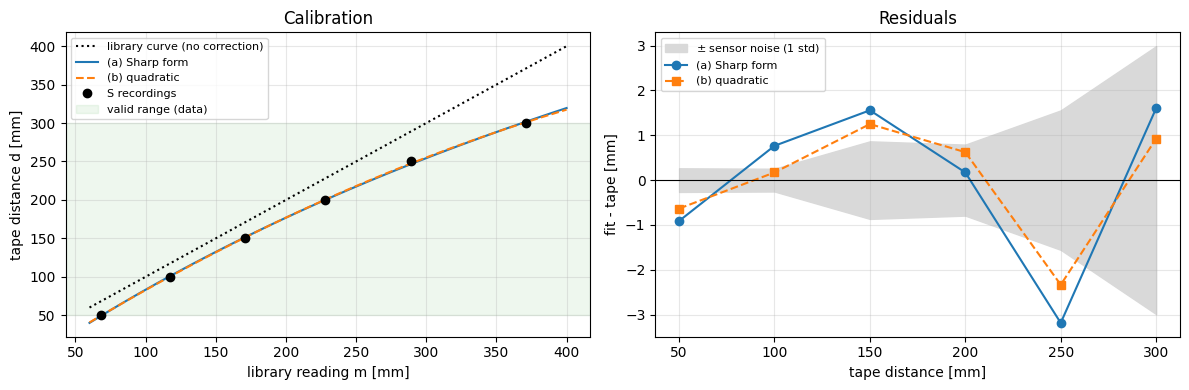

In [3]:
SHARP_A, SHARP_B = 24.7694, 0.0109311               # library curve (sharp41S.cpp): m = SHARP_A / raw + SHARP_B
TAPE_MM = [50, 100, 150, 200, 250, 300]             # data/A3/S_<d>mm.csv

rows = []
for d in TAPE_MM:
    m = load_log(DATA_A3 / f'S_{d}mm.csv', firmware='identification_a3').front.values
    raw = SHARP_A / (m - SHARP_B)                   # ADC counts
    rows.append(dict(tape=d / 1e3, m=m.mean(), m_std=m.std(), raw=raw.mean(), raw_std=raw.std(), n=len(m),
                     whole_counts=np.allclose(raw, np.round(raw), atol=1e-2), dropouts=int((m > 1).sum())))
stat = pd.DataFrame(rows)

# (a) Sharp form on the recovered ADC value, (b) quadratic in m
sharp = lambda raw, a, k, b: a / (raw + k) + b
p_sharp, _ = curve_fit(sharp, stat.raw, stat.tape, p0=[SHARP_A, 0, 0])
CAL_C2, CAL_C1, CAL_C0 = np.polyfit(stat.m, stat.tape, 2)
calibrate = lambda m: (CAL_C2 * m + CAL_C1) * m + CAL_C0          # the firmware evaluates it the same way
dd_dm = lambda m: 2 * CAL_C2 * m + CAL_C1                          # slope of the calibration

def loo(fit_predict):
    # leave-one-out: fit on 5 points, predict the 6th
    out = []
    for i in range(len(stat)):
        k = np.arange(len(stat)) != i
        out.append(fit_predict(stat[k], stat.iloc[i]))
    return np.array(out)
loo_a = loo(lambda s, r: sharp(r.raw, *curve_fit(sharp, s.raw, s.tape, p0=[SHARP_A, 0, 0], maxfev=20000)[0]))
loo_b = loo(lambda s, r: np.polyval(np.polyfit(s.m, s.tape, 2), r.m))

tab = pd.DataFrame({
    'tape [mm]': 1e3 * stat.tape, 'library m [mm]': 1e3 * stat.m, 'bias [mm]': 1e3 * (stat.m - stat.tape),
    'std m [mm]': 1e3 * stat.m_std, 'std raw [counts]': stat.raw_std,
    'resid (a) [mm]': 1e3 * (sharp(stat.raw, *p_sharp) - stat.tape), 'resid (b) [mm]': 1e3 * (calibrate(stat.m) - stat.tape),
    'noise after cal. [mm]': 1e3 * dd_dm(stat.m) * stat.m_std,
    'LOO (a) [mm]': 1e3 * (loo_a - stat.tape), 'LOO (b) [mm]': 1e3 * (loo_b - stat.tape)})
print(tab.round(2).to_string(index=False))
print(f"\nwhole ADC counts in every file: {stat.whole_counts.all()};  drop-outs: {stat.dropouts.sum()}")
for name, col, lcol in [('(a) Sharp form', 'resid (a) [mm]', 'LOO (a) [mm]'), ('(b) quadratic ', 'resid (b) [mm]', 'LOO (b) [mm]')]:
    print(f'{name}: residual rms {np.sqrt(np.mean(tab[col]**2)):.2f} mm, leave-one-out rms {np.sqrt(np.mean(tab[lcol]**2)):.2f} mm')
print(f'-> quadratic: d = {CAL_C2:.6f} m^2 + {CAL_C1:.6f} m + {CAL_C0:.6f}  [m]')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mm = np.linspace(0.06, 0.40, 300)
ax[0].plot(1e3 * mm, 1e3 * mm, 'k:', label='library curve (no correction)')
ax[0].plot(1e3 * mm, 1e3 * sharp(SHARP_A / (mm - SHARP_B), *p_sharp), label='(a) Sharp form')
ax[0].plot(1e3 * mm, 1e3 * calibrate(mm), '--', label='(b) quadratic')
ax[0].plot(1e3 * stat.m, 1e3 * stat.tape, 'ko', label='S recordings')
ax[0].axhspan(50, 300, color='tab:green', alpha=0.08, label='valid range (data)')
ax[0].set(xlabel='library reading m [mm]', ylabel='tape distance d [mm]', title='Calibration'); ax[0].legend(fontsize=8)
noise = tab['noise after cal. [mm]']
ax[1].fill_between(tab['tape [mm]'], -noise, noise, color='0.85', label=r'$\pm$ sensor noise (1 std)')
ax[1].plot(tab['tape [mm]'], tab['resid (a) [mm]'], 'o-', label='(a) Sharp form')
ax[1].plot(tab['tape [mm]'], tab['resid (b) [mm]'], 's--', label='(b) quadratic')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set(xlabel='tape distance [mm]', ylabel='fit - tape [mm]', title='Residuals'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Choice: (b) quadratic.** It has the smaller residuals (fit and leave-one-out), and it costs two multiplications on the Arduino. The residuals (rms 1.2 mm, max 2.3 mm) are larger than the sensor noise at some distances, but each point is the mean of thousands of samples, so its own noise is negligible: the residuals show how exactly the robot was placed at the tape mark, and they are consistent with a ruler/placement uncertainty of 3–5 mm. A better fit than that is not possible with this data. Leaving out the 300 mm point gives the largest error, so the curve must not be used outside 50–300 mm.

### 2.3 Measurement noise $R(d)$

The noise is ADC **quantisation**: the reading moves by about one count. Since $m \propto 1/\text{raw}$, one count is worth $\Delta m = (m-0.0109)^2/24.7694$ metres, which grows with $d^2$; after calibration it is multiplied by the slope $\mathrm d d/\mathrm d m$:

$$\sigma_d(m) = c\,\frac{\mathrm d d}{\mathrm d m}\,\frac{(m-0.0109)^2}{24.7694},\qquad R(d) = \sigma_d^2 + \sigma_\text{cal}^2$$

$c$ [counts] is fitted on the S recordings (in log space, so every distance counts equally). $\sigma_\text{cal} = 2$ mm is a floor for the calibration error (residual rms 1.2 mm, max ~3 mm). Adding it to $R$ as if it were white noise is a pragmatic approximation: the calibration error is systematic, not white. The filter evaluates $R$ at every step, also for the gate's innovation test.

NOISE_C = 0.830 counts   (per distance: 1.86, 0.56, 0.92, 0.51, 0.69, 0.97)
 tape [mm]  measured std [mm]  model std [mm]  sqrt(R) incl. floor [mm]  R model [m^2]
      50.0            0.26376         0.11754                   2.00345        0.00000
     100.0            0.25367         0.37664                   2.03516        0.00000
     150.0            0.86506         0.77931                   2.14647        0.00000
     200.0            0.79172         1.29170                   2.38086        0.00001
     250.0            1.55459         1.86827                   2.73687        0.00001
     300.0            2.98690         2.55556                   3.24513        0.00001


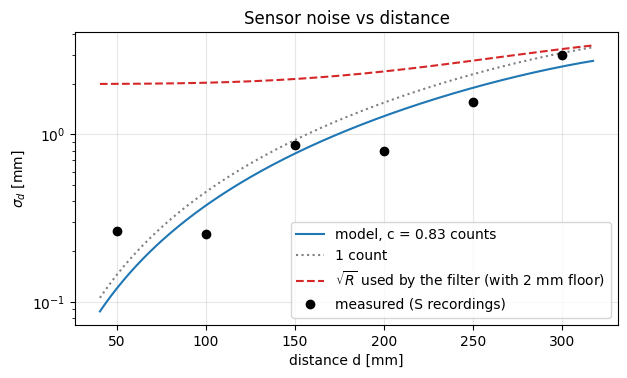

In [4]:
dm_per_count = lambda m: (m - SHARP_B)**2 / SHARP_A                       # library metres per ADC count
NOISE_C = np.exp(np.mean(np.log(stat.m_std / dm_per_count(stat.m))))     # [counts]
sigma_d = lambda m: NOISE_C * dd_dm(m) * dm_per_count(m)                  # [m]
SIGMA_CAL = 0.002                                                         # [m] calibration floor
R_of_m = lambda m: sigma_d(m)**2 + SIGMA_CAL**2                           # [m^2]
H = -R_WHEEL                                                              # z = d = H x

meas = 1e3 * dd_dm(stat.m) * stat.m_std
print(f'NOISE_C = {NOISE_C:.3f} counts   (per distance: {", ".join(f"{c:.2f}" for c in stat.m_std / dm_per_count(stat.m))})')
print(pd.DataFrame({'tape [mm]': 1e3 * stat.tape, 'measured std [mm]': meas, 'model std [mm]': 1e3 * sigma_d(stat.m), 'sqrt(R) incl. floor [mm]': 1e3 * np.sqrt(R_of_m(stat.m)),
                    'R model [m^2]': R_of_m(stat.m)}).round(5).to_string(index=False))

mm = np.linspace(0.06, 0.40, 300)
plt.figure(figsize=(7, 3.8))
plt.semilogy(1e3 * calibrate(mm), 1e3 * sigma_d(mm), label=f'model, c = {NOISE_C:.2f} counts')
plt.semilogy(1e3 * calibrate(mm), 1e3 * dd_dm(mm) * dm_per_count(mm), ':', color='0.5', label='1 count')
plt.semilogy(1e3 * calibrate(mm), 1e3 * np.sqrt(R_of_m(mm)), '--', color='tab:red', label=r'$\sqrt{R}$ used by the filter (with 2 mm floor)')
plt.semilogy(1e3 * stat.tape, meas, 'ko', label='measured (S recordings)')
plt.xlabel('distance d [mm]'); plt.ylabel(r'$\sigma_d$ [mm]'); plt.title('Sensor noise vs distance'); plt.legend(); plt.show()

### 2.4 Process noise $\mathbf Q(\omega)$: slip grows with speed

The odometry error changes sign between sessions: +0.7 % in Assignment 2 (R4), −0.6 … −3.6 % on the wall drives W1–W3. So it is not a wheel-radius error (that would always have the same sign) but random slip, which only happens while the wheels turn and grows with the speed. The speed noise is therefore modelled as $\sigma_\omega^2 + (k\,\omega)^2$, with $\omega = (\omega_A+\omega_B)/2$:

$$\mathbf Q_k = \mathbf B\,\big(\sigma_\omega^2 + (k\,\omega_k)^2\big)\,\mathbf B^\mathsf T = \Delta t^2\big(\sigma_\omega^2 + (k\,\omega_k)^2\big)$$

$\sigma_\omega$ is the A2 value (the robot standing still adds almost nothing, as the encoders do not move). $k$ is chosen on the real drives in section 5: $k = 0.10$ gives a mean NIS ≈ 1 while driving.

In [5]:
K_SLIP = 0.10                                                     # [-] chosen in section 5 (W1-W3)
Q_w = lambda w: DT**2 * (SIGMA_OMEGA**2 + (K_SLIP * w)**2)        # [rad^2] per step, w = mean wheel speed [rad/s]
for w in [0, 3, 7]:
    print(f'w = {w} rad/s: Q = {Q_w(w):.2e} rad^2 = {Q_w(w)/Q:5.1f} x A2 Q')

w = 0 rad/s: Q = 3.30e-06 rad^2 =   1.0 x A2 Q
w = 3 rad/s: Q = 1.23e-05 rad^2 =   3.7 x A2 Q
w = 7 rad/s: Q = 5.23e-05 rad^2 =  15.9 x A2 Q


## 3. The filter and a simulated wall approach
Order as in `robot.cpp`: **correction** with the new measurement, then **prediction** to the next sample. An optional **gate**, identical to `CorrectionUpdate` in the firmware, calibrates every reading first and skips the update for drop-outs (24.78 m), NaN/inf and readings above 0.40 m (raw value: the calibration is fitted up to 0.371 m, and beyond 30 cm the sensor over-reads instead of dropping out), for **calibrated** distances outside 0.04–0.32 m (sensor range 0.04–0.30 m plus margin) and for innovations above 3σ ($\nu^2/S>9$). If more than 20 samples in a row (0.2 s) fail the 3σ test, the measurement is accepted again and $P$ is first widened to $P_\text{resync}=9.5$ rad² ($\approx$ 10 cm): then the *estimate* is wrong, not the sensor (e.g. a wrong initial guess), and a pure 3σ gate would lock the filter out forever. The counter starts at 0 for every run (`ResetGate()`).

The simulation drives from 0.30 m (the edge of the sensor range) to about 0.10 m (still, accelerate to 3 rad/s, cruise, brake), with a simulated sensor that works like the real one (true distance + a **calibration error** → ADC counts with $c$ counts of noise → whole counts → library curve). The calibration error is a smooth bias, drawn per run: values ~N(0, 2 mm) at 50, 100, … 300 mm, linearly interpolated, so each run has its own systematic error like a real calibration, 1.5 % drop-outs reading 24.78 m, the measured wheel-speed noise, and a **5 % wheel-speed scale error** that the filter does not know about. As on the robot, the filter starts from the **tape-measured start distance** (typed in ValueOut1), simulated with a ruler error of $\sigma_\text{ruler}=5$ mm (assumed), so $P_0=(\sigma_\text{ruler}/R_\text{wheel})^2$, the firmware value. Section 3.1 also starts from a *deliberately wrong* estimate to show the re-sync.

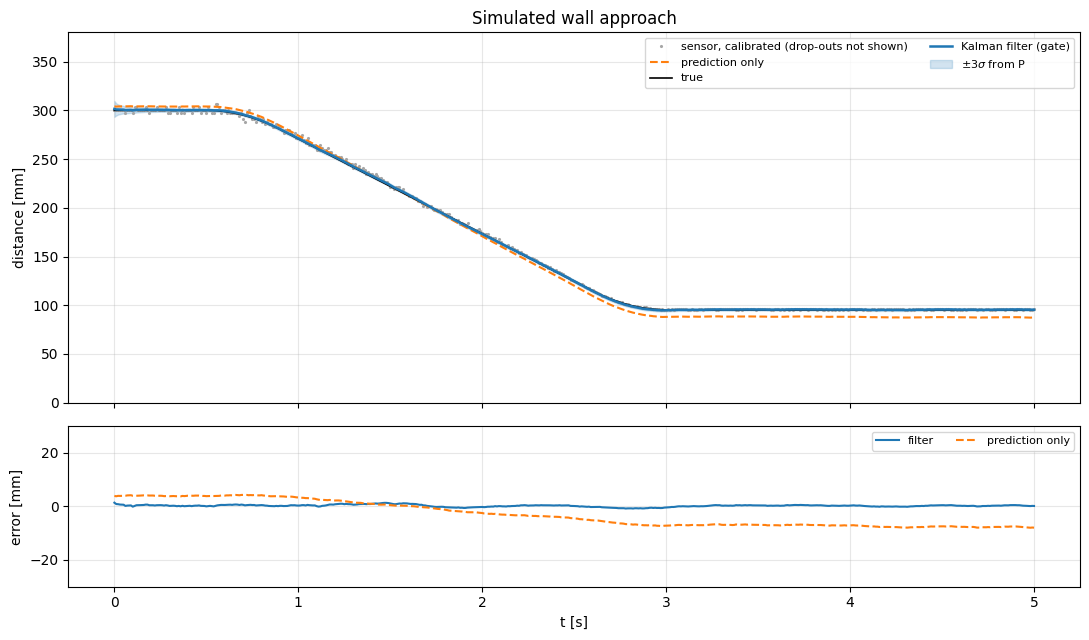

In [6]:
def lkf(m, w_mean, Q, x0, P0, gate=None, r_scale=1.0, r_func=None):
    # Same steps as robot.cpp + state_estimator.cpp. m = getFrontDistance() [m], w_mean = (wA + wB)/2 [rad/s]
    # state x = -d/R_WHEEL [rad]; Q is a number or a function of the wheel speed; r_func replaces R(d) if given
    n = len(m); o = {k: np.zeros(n) for k in ['x', 'P', 'xb', 'Pb', 'nu', 'S', 'K', 'z', 'R']}; o['skip'] = np.zeros(n, bool)
    o['rej_range'], o['rej_3s'], o['resync'] = np.zeros(n, bool), np.zeros(n, bool), np.zeros(n, bool)
    x, P, rejected = x0, P0, 0                                 # rejected = 0: ResetGate()
    for k in range(n):
        o['xb'][k], o['Pb'][k] = x, P
        z = calibrate(m[k]); Rk = r_scale * (r_func or R_of_m)(m[k])         # calibrated distance [m] and R(d) [m^2]
        nu = z - H * x; S = H * P * H + Rk
        accept = True
        if gate is not None:                                   # same logic as CorrectionUpdate in the C++
            if not (SHARP_B < m[k] < M_RAW_MAX):
                accept = False                                 # drop-out, NaN/inf (raw value)
            elif not (D_MIN <= z <= D_MAX):
                accept = False                                 # outside the sensor range (calibrated)
                o['rej_range'][k] = True
            elif nu**2 > gate * S:
                rejected += 1
                accept = rejected > MAX_REJECT                 # persistent: the estimate is wrong, re-sync
                if accept:
                    P = P_RESYNC; S = H * P * H + Rk           # re-sync: widen P first, as in the firmware
                    o['resync'][k] = True
                else:
                    o['rej_3s'][k] = True
            if accept:
                rejected = 0
        if not accept:
            K = 0.0; o['skip'][k] = True
        else:
            K = P * H / S
        x = x + K * nu; P = (1 - K * H) * P
        o['x'][k], o['P'][k], o['nu'][k], o['S'][k], o['K'][k], o['z'][k], o['R'][k] = x, P, nu, S, K, z, Rk
        Qk = Q(w_mean[k]) if callable(Q) else Q
        x = F * x + B * w_mean[k]; P = F * P * F + Qk                     # prediction (v = mean wheel speed)
    return o

GATE, SIG_RULER, W_CRUISE = 9.0, 0.005, 3.0                                # ruler uncertainty of the start distance [m] (assumed)
M_RAW_MAX, D_MIN, D_MAX, MAX_REJECT = 0.40, 0.04, 0.32, 20                 # raw limit [m]; calibrated range [m]; re-sync after 0.2 s
P0_STATE = (SIG_RULER / R_WHEEL)**2                                        # [rad^2] = P0_STATE in state_estimator.h
P_RESYNC = 9.5                                                             # [rad^2] = P_RESYNC in state_estimator.h, ~(0.10 m / R_WHEEL)^2
P0 = P0_STATE
SIG_W_ENC = SIGMA_OMEGA                                                    # wheel-speed noise [rad/s] from section 2.1

m_grid = np.linspace(SHARP_B + 0.03, 0.70, 20000); d_grid = calibrate(m_grid)        # one-to-one up to 0.70 m; beyond 0.30 m the
# simulated sensor over-reads like the real one (m > M_RAW_MAX -> rejected by the gate)
CAL_KNOTS = np.array(TAPE_MM) / 1e3                                        # [m] where the calibration error is drawn
def sensor(d_true, rng, cal_bias):
    # library reading m for a true distance: + calibration error -> inverse calibration -> ADC counts + noise
    # -> whole counts -> library curve
    d_seen = d_true + np.interp(d_true, CAL_KNOTS, cal_bias)                # smooth systematic error of this run
    raw = SHARP_A / (np.interp(d_seen, d_grid, m_grid) - SHARP_B)
    raw = np.round(raw + rng.normal(0, np.sqrt(max(NOISE_C**2 - 1/12, 0)), len(raw)))   # rounding adds 1/12 count^2
    return SHARP_A / raw + SHARP_B

def simulate(seed, d0=0.30, T=5.0, eps=0.05, p_drop=0.015):
    rng = np.random.default_rng(seed); n = int(round(T/DT)) + 1; tt = np.arange(n) * DT
    w_true = np.interp(tt, [0, .5, .9, 2.6, 3.0, T], [0, 0, W_CRUISE, W_CRUISE, 0, 0])
    d_true = d0 - R_WHEEL * np.concatenate([[0], np.cumsum(0.5 * (w_true[1:] + w_true[:-1]) * DT)])
    w_meas = (1 + eps) * w_true + rng.normal(0, SIG_W_ENC, n)
    cal_bias = rng.normal(0, SIGMA_CAL, len(CAL_KNOTS))                    # calibration error of this run [m]
    z = sensor(d_true, rng, cal_bias); z[rng.random(n) < p_drop] = 24.78
    x0 = (d0 + rng.normal(0, SIG_RULER)) / -R_WHEEL                       # tape-measured start, typed in ValueOut1 (Meas2State)
    return dict(t=tt, d=d_true, w=w_meas, z=z, x0=x0)

sim = simulate(3); tt, d_true, z, wm, X0 = sim['t'], sim['d'], sim['z'], sim['w'], sim['x0']
f_plain, f_gate = lkf(z, wm, Q_w, X0, P0), lkf(z, wm, Q_w, X0, P0, gate=GATE)
d_pred = H * (X0 + B * np.concatenate([[0], np.cumsum(wm[:-1])]))        # prediction only, in metres

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ok = z < M_RAW_MAX
ax[0].plot(tt[ok], 1e3*calibrate(z[ok]), '.', ms=2.5, color='0.65', label='sensor, calibrated (drop-outs not shown)')
ax[0].plot(tt, 1e3*d_pred, '--', color='tab:orange', label='prediction only')
ax[0].plot(tt, 1e3*d_true, 'k', lw=1.2, label='true'); ax[0].plot(tt, 1e3*H*f_gate['x'], 'tab:blue', lw=1.8, label='Kalman filter (gate)')
sd = R_WHEEL*np.sqrt(f_gate['P']); ax[0].fill_between(tt, 1e3*(H*f_gate['x']-3*sd), 1e3*(H*f_gate['x']+3*sd), color='tab:blue', alpha=.2, label=r'$\pm3\sigma$ from P')
ax[0].set(ylim=(0, 380), ylabel='distance [mm]', title='Simulated wall approach'); ax[0].legend(ncol=2, fontsize=8)
ax[1].plot(tt, 1e3*(H*f_gate['x']-d_true), label='filter'); ax[1].plot(tt, 1e3*(d_pred-d_true), '--', color='tab:orange', label='prediction only')
ax[1].set(ylim=(-30, 30), xlabel='t [s]', ylabel='error [mm]'); ax[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Why the gate is needed, Gaussian picture, and consistency

drop-out at t = 2.12 s: sensor reads 24.78 m; innovation = 1 sigma
estimate jump without gate: 0 mm, with gate: 0.0 mm


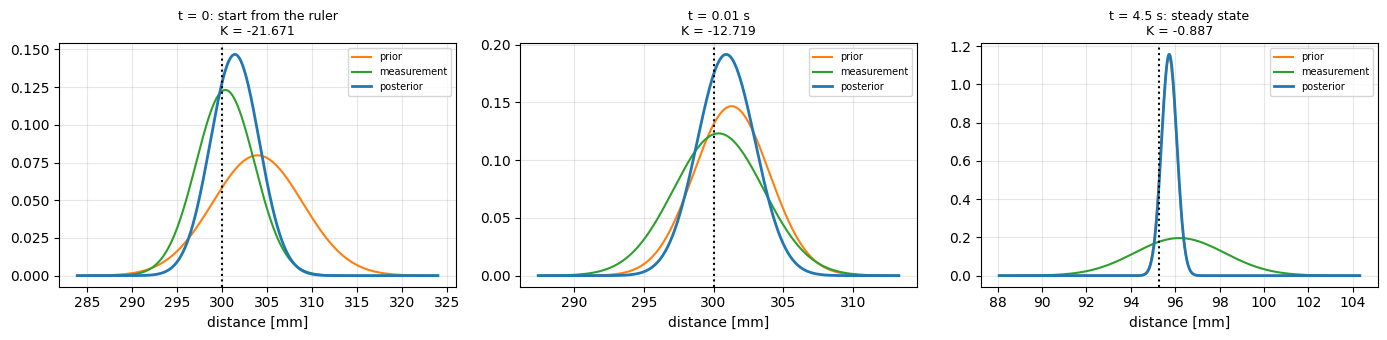

mean NIS = 0.26 (ideal 1);  share above the 95 % chi2 limit = 0.3 % (ideal 5 %)
gate: 0.00 % of the in-range readings rejected by the 3-sigma test; re-syncs per run: mean 0.00, max 0
deliberately wrong start 0 m, true 300 mm -> final error: pure 3-sigma gate -312 mm, gate with re-sync +0.2 mm


In [7]:
k = int(np.flatnonzero((z > 1) & (tt > 1.0))[0])
print(f'drop-out at t = {tt[k]:.2f} s: sensor reads {z[k]:.2f} m; innovation = {abs(f_plain["nu"][k]/np.sqrt(f_plain["S"][k])):.0f} sigma')
print(f'estimate jump without gate: {1e3*R_WHEEL*abs(f_plain["x"][k]-f_plain["xb"][k]):.0f} mm, with gate: {1e3*R_WHEEL*abs(f_gate["x"][k]-f_gate["xb"][k]):.1f} mm')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, kk, ttl in zip(ax, [0, 1, 450], ['t = 0: start from the ruler', 't = 0.01 s', 't = 4.5 s: steady state']):
    o = f_gate; m_pr, s_pr, m_po, s_po = H*o['xb'][kk], R_WHEEL*np.sqrt(o['Pb'][kk]), H*o['x'][kk], R_WHEEL*np.sqrt(o['P'][kk])
    zk, sk = o['z'][kk], np.sqrt(o['R'][kk])                     # calibrated reading and its std
    xs = np.linspace(min(m_pr-4*s_pr, zk-4*sk), max(m_pr+4*s_pr, zk+4*sk), 600)
    a.plot(1e3*xs, norm.pdf(xs, m_pr, s_pr)/1e3, 'tab:orange', label='prior'); a.plot(1e3*xs, norm.pdf(xs, zk, sk)/1e3, 'tab:green', label='measurement')
    a.plot(1e3*xs, norm.pdf(xs, m_po, s_po)/1e3, 'tab:blue', lw=2, label='posterior'); a.axvline(1e3*d_true[kk], color='k', ls=':')
    a.set_title(ttl + f'\nK = {o["K"][kk]:.3f}', fontsize=9); a.set_xlabel('distance [mm]'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# consistency: normalised innovation squared over many runs (drop-outs excluded), expected mean 1
# and how often the gate rejects a reading that is in range (3-sigma test) or re-syncs
nis, n_inrange, n_3s, n_resync = [], 0, 0, []
for s in range(40):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE); keep = ~o['skip'] & (sm['t'] > 1)
    nis.append((o['nu']**2 / o['S'])[keep])
    inrange = (sm['z'] < M_RAW_MAX) & ~o['rej_range']
    n_inrange += inrange.sum(); n_3s += o['rej_3s'].sum(); n_resync.append(o['resync'].sum())
nis = np.concatenate(nis)
print(f'mean NIS = {nis.mean():.2f} (ideal 1);  share above the 95 % chi2 limit = {100*(nis > chi2.ppf(.95, 1)).mean():.1f} % (ideal 5 %)')
print(f'gate: {100*n_3s/n_inrange:.2f} % of the in-range readings rejected by the 3-sigma test; '
      f're-syncs per run: mean {np.mean(n_resync):.2f}, max {np.max(n_resync)}')

# DELIBERATELY WRONG initial estimate (ValueOut1 left at 0), to demonstrate the re-sync:
# a pure 3-sigma gate never accepts a measurement again
def plain_3sigma_gate(m, w, x0):
    x, P = x0, P0
    for k in range(len(m)):
        zk = calibrate(m[k]); nu = zk - H * x; S = H * P * H + R_of_m(m[k])
        if SHARP_B < m[k] < M_RAW_MAX and D_MIN <= zk <= D_MAX and nu**2 <= GATE * S:
            K = P * H / S; x += K * nu; P = (1 - K * H) * P
        x += B * w[k]; P += Q_w(w[k])
    return H * x
bad = 0.0 / -R_WHEEL + 1e-9
print(f'deliberately wrong start 0 m, true {1e3*d_true[0]:.0f} mm -> final error: pure 3-sigma gate {1e3*(plain_3sigma_gate(z, wm, bad) - d_true[-1]):+.0f} mm, '
      f'gate with re-sync {1e3*(H*lkf(z, wm, Q_w, bad, P0, gate=GATE)["x"][-1] - d_true[-1]):+.1f} mm')

## 4. Tuning check and comparison
RMSE after the start-up transient ($t>1$ s) over 100 simulated runs, and the sensitivity to scaling $Q$ and $R$. Starting outside the sensor range (e.g. 0.45 m) means prediction only until the wall comes into range, so the error of the start estimate and the drift of the wheel-speed error stay uncorrected until then (last line below): the filter can only correct what the sensor can see.

                                        median RMSE [mm]  95th pct [mm]
sensor, calibrated (drop-outs removed)               1.6            2.9
prediction only                                      9.2           17.0
LKF (no gate)                                        1.5            2.8
LKF + gate                                           1.5            2.8


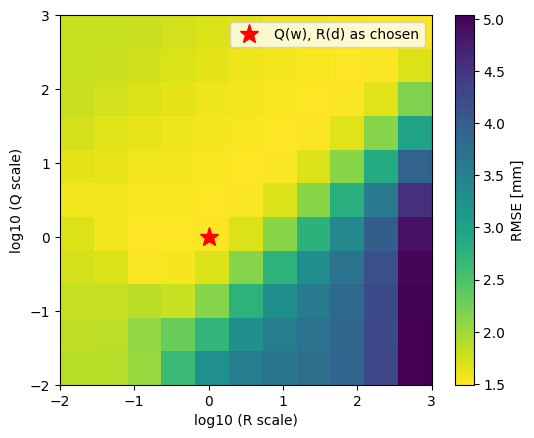

best on grid: Q x 1, R x 0.1 -> 1.5 mm;  data values (x1, x1): 1.5 mm


LKF + gate, median RMSE: start at 0.30 m 1.5 mm, start at 0.45 m (outside the sensor range) 2.9 mm


In [8]:
res = {k: [] for k in ['sensor, calibrated (drop-outs removed)', 'prediction only', 'LKF (no gate)', 'LKF + gate']}
for s in range(100):
    sm = simulate(s); m = sm['t'] > 1; ok = sm['z'] < M_RAW_MAX; e = lambda est: np.sqrt(np.mean((est - sm['d'])[m]**2))
    res['sensor, calibrated (drop-outs removed)'].append(np.sqrt(np.mean((calibrate(sm['z']) - sm['d'])[m & ok]**2)))
    res['prediction only'].append(e(H * (sm['x0'] + B * np.concatenate([[0], np.cumsum(sm['w'][:-1])]))))
    res['LKF (no gate)'].append(e(H * lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0)['x'])); res['LKF + gate'].append(e(H * lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE)['x']))
print(pd.DataFrame({k: [1e3*np.median(v), 1e3*np.percentile(v, 95)] for k, v in res.items()}, index=['median RMSE [mm]', '95th pct [mm]']).T.round(1).to_string())

def rmse_scaled(s, qm, rm):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], lambda w: qm * Q_w(w), sm['x0'], P0, gate=GATE, r_scale=rm)
    return np.sqrt(np.mean((H * o['x'] - sm['d'])[sm['t'] > 1]**2))
sc = np.logspace(-2, 3, 11); grid = np.zeros((len(sc), len(sc)))
for i, qm in enumerate(sc):
    for j, rm in enumerate(sc):
        grid[i, j] = np.mean([rmse_scaled(s, qm, rm) for s in range(8)])
plt.figure(figsize=(6, 4.8)); plt.imshow(1e3*grid, origin='lower', extent=[-2, 3, -2, 3], cmap='viridis_r', aspect='auto'); plt.plot(0, 0, 'r*', ms=14, label='Q(w), R(d) as chosen')
plt.colorbar(label='RMSE [mm]'); plt.xlabel('log10 (R scale)'); plt.ylabel('log10 (Q scale)'); plt.legend(); plt.grid(False); plt.show()
i, j = np.unravel_index(grid.argmin(), grid.shape)
print(f'best on grid: Q x {sc[i]:.2g}, R x {sc[j]:.2g} -> {1e3*grid[i,j]:.1f} mm;  data values (x1, x1): {1e3*grid[5,5]:.1f} mm')

# Starting outside the sensor range: same runs, but from 0.45 m
def rmse_start(d0):
    r = []
    for s in range(100):
        sm = simulate(s, d0=d0); o = lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE)
        r.append(np.sqrt(np.mean((H * o['x'] - sm['d'])[sm['t'] > 1]**2)))
    return 1e3 * np.median(r)
print(f'LKF + gate, median RMSE: start at 0.30 m {rmse_start(0.30):.1f} mm, start at 0.45 m (outside the sensor range) {rmse_start(0.45):.1f} mm')

## 5. Validation on the real wall drives W1–W3

`data/A3/W<n>_start<mm>_end<mm>.csv`: button 1 of `test_firmware/INTERNAL-Identification-A3`, 3.5 V, start 300 mm, stop when the sensor reads < 80 mm, then coasting to 42–45 mm (tape). Each drive is replayed offline through the same filter as the firmware, started from the tape distance with $P_0$.

The only ground truth is the tape at the start and at the end. During the drive the **reference** is the odometry rescaled so that it matches the tape travel of that run (assumes the slip is spread evenly over the drive). Metrics: error at the end vs tape, RMS vs the reference, mean NIS and mean innovation **while driving** (standing still, the innovations only contain ADC noise), and gate rejections / re-syncs.

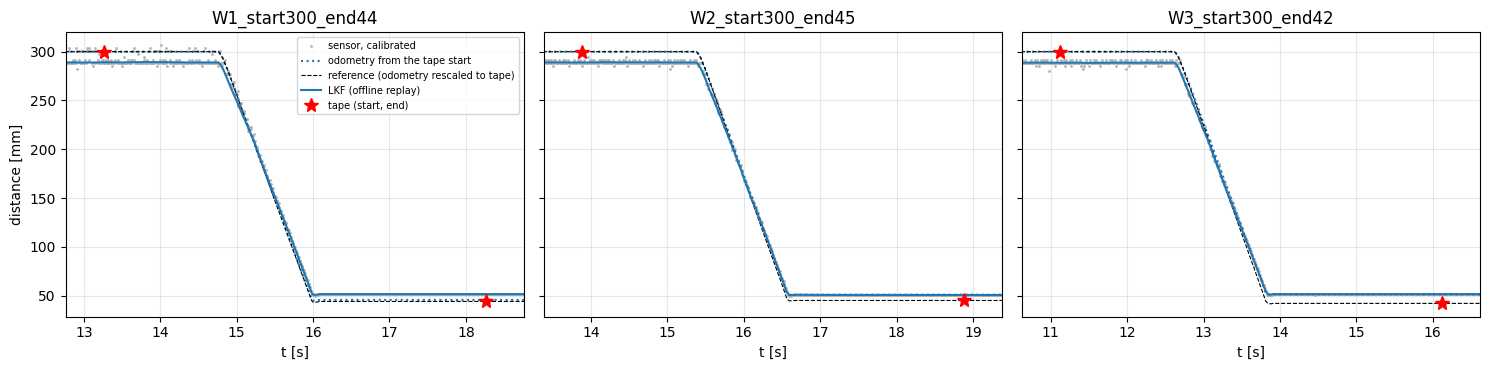

Final filter: Q(w) with k = 0.10, R(d) with sigma_cal = 2 mm. Errors in mm (+ = estimate further from the wall than the tape).
              run  end_err  rms_ref  nis_drive  drift  rej_3s  rej_3s_drive  resync  rej_range  sensor_start_err  sensor_end_err  odo_end_err
W1_start300_end44     7.45     8.94       1.08   1.39     316             9       0          0            -11.57            7.43         1.59
W2_start300_end45     5.60     9.37       0.86   0.93       0             0       0          0            -11.57            5.54         5.90
W3_start300_end42     9.47    10.47       0.78   0.92       3             1       0          0            -11.57            9.43         9.30


In [9]:
def load_w(path):
    mt = re.match(r'W(\d+)_start(\d+)_end(\d+)', path.stem)
    df = load_log(path, firmware='identification_a3')
    w = ((df.wA + df.wB) / 2).values
    mv = np.flatnonzero(np.abs(w) > 0)
    return dict(name=path.stem, t=df.t.values, m=df.front.values, w=w, d_start=int(mt[2]) / 1e3, d_end=int(mt[3]) / 1e3,
                drive=slice(mv[0], mv[-1] + 30))                            # wheels turning + 0.3 s

def w_metrics(r, Q, r_func=None):
    o = lkf(r['m'], r['w'], Q, r['d_start'] / -R_WHEEL, P0, gate=GATE, r_func=r_func)
    odo = R_WHEEL * DT * np.concatenate([[0], np.cumsum(r['w'][:-1])])
    ref = r['d_start'] - odo * (r['d_start'] - r['d_end']) / (R_WHEEL * DT * r['w'].sum())   # odometry rescaled to the tape
    acc = ~o['skip'][r['drive']]
    return o, dict(end_err=1e3 * (H * o['x'][-1] - r['d_end']), rms_ref=1e3 * np.sqrt(np.mean((H * o['x'] - ref)**2)),
                   nis_drive=np.mean((o['nu']**2 / o['S'])[r['drive']][acc]), drift=1e3 * np.mean(o['nu'][r['drive']][acc]),
                   rej_3s=int(o['rej_3s'].sum()), rej_3s_drive=int(o['rej_3s'][r['drive']].sum()), resync=int(o['resync'].sum()),
                   rej_range=int(o['rej_range'].sum())), ref

WRUNS = [load_w(p) for p in sorted(DATA_A3.glob('W*_start*_end*.csv'))]
rows = []
fig, ax = plt.subplots(1, len(WRUNS), figsize=(15, 3.8), sharey=True)
for a, r in zip(np.atleast_1d(ax), WRUNS):
    o, met, ref = w_metrics(r, Q_w)
    ok = r['m'] < M_RAW_MAX
    odo_tape = r['d_start'] - R_WHEEL * DT * np.concatenate([[0], np.cumsum(r['w'][:-1])])
    a.plot(r['t'][ok], 1e3 * calibrate(r['m'][ok]), '.', ms=2, color='0.7', label='sensor, calibrated')
    a.plot(r['t'], 1e3 * odo_tape, ':', label='odometry from the tape start')
    a.plot(r['t'], 1e3 * ref, '--', color='k', lw=0.8, label='reference (odometry rescaled to tape)')
    a.plot(r['t'], 1e3 * H * o['x'], 'tab:blue', label='LKF (offline replay)')
    t0 = r['t'][r['drive']][0]; a.set_xlim(t0 - 2, t0 + 4); a.set(title=r['name'], xlabel='t [s]')
    a.plot([t0 - 1.5, t0 + 3.5], [1e3 * r['d_start'], 1e3 * r['d_end']], 'r*', ms=10, label='tape (start, end)')
    end_sensor = 1e3 * (np.median(calibrate(r['m'][-100:])) - r['d_end'])
    start_sensor = 1e3 * (np.median(calibrate(r['m'][r['t'] < t0 - 0.5])) - r['d_start'])
    rows.append(dict(run=r['name'], **met, sensor_start_err=start_sensor, sensor_end_err=end_sensor,
                     odo_end_err=1e3 * (odo_tape[-1] - r['d_end'])))
np.atleast_1d(ax)[0].set_ylabel('distance [mm]'); np.atleast_1d(ax)[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Final filter: Q(w) with k = %.2f, R(d) with sigma_cal = %.0f mm. Errors in mm (+ = estimate further from the wall than the tape).' % (K_SLIP, 1e3 * SIGMA_CAL))
print(pd.DataFrame(rows).round(2).to_string(index=False))

### 5.1 Choice of $\mathbf Q$

Compared on the same drives (with $R(d)$, $\sigma_\text{cal}$ = 2 mm): the constant A2 $\mathbf Q$, $\mathbf Q\times10$, and $\mathbf Q(\omega)$ with $k$ from two fits:

* $k$ from the **odometry end errors** (−1.6/−5.9/−9.3 mm vs tape): the $k$ for which the accumulated variance $\sum(k\,\omega\,\Delta t)^2$ matches the mean squared end error;
* $k$ from **consistency**: mean NIS ≈ 1 while driving (scan below).

In [10]:
# k from the odometry end errors (white per-step noise k*|w| that reproduces the end-error rms)
num, den, qs = [], [], []
for r in WRUNS:
    i = np.flatnonzero(np.abs(r['w']) > 0); i0, i1 = i[0], i[-1]
    err = R_WHEEL * DT * r['w'].sum() - (r['d_start'] - r['d_end'])
    num.append((err / R_WHEEL)**2); den.append(np.sum((r['w'][i0:i1 + 1] * DT)**2)); qs.append((i1 - i0 + 1) * (SIGMA_OMEGA * DT)**2)
K_END = np.sqrt(max((np.mean(num) - np.mean(qs)) / np.mean(den), 0))
print(f'odometry end errors {", ".join(f"{1e3*R_WHEEL*np.sqrt(v):.1f}" for v in num)} mm -> k from end errors = {K_END:.2f}\n')

print('k scan, NIS / mean innovation / 3-sigma rejections while driving, per run:')
for kk in [0.05, 0.10, 0.15, 0.20, K_END]:
    ms = [w_metrics(r, lambda w, kk=kk: DT**2 * (SIGMA_OMEGA**2 + (kk * w)**2))[1] for r in WRUNS]
    print(f'  k = {kk:.2f}: NIS {" ".join(f"{m["nis_drive"]:.2f}" for m in ms)} (mean {np.mean([m["nis_drive"] for m in ms]):.2f}),'
          f' drift {" ".join(f"{m["drift"]:+.1f}" for m in ms)} mm, rejections {" ".join(str(m["rej_3s_drive"]) for m in ms)}')

variants = {'A2 Q (constant)': Q, 'A2 Q x 10': 10 * Q,
            f'Q(w), k = {K_END:.2f} (end errors)': lambda w: DT**2 * (SIGMA_OMEGA**2 + (K_END * w)**2),
            f'Q(w), k = {K_SLIP:.2f} (chosen)': Q_w}
rows = []
for name, qv in variants.items():
    ms = [w_metrics(r, qv)[1] for r in WRUNS]
    rows.append({'Q': name, 'end error [mm]': ' '.join(f'{m["end_err"]:+.1f}' for m in ms),
                 'RMS vs ref [mm]': np.mean([m['rms_ref'] for m in ms]), 'NIS driving': np.mean([m['nis_drive'] for m in ms]),
                 'drift [mm]': np.mean([m['drift'] for m in ms]), '3-sigma rej. (driving/all)': f"{sum(m['rej_3s_drive'] for m in ms)}/{sum(m['rej_3s'] for m in ms)}",
                 're-syncs': sum(m['resync'] for m in ms)})
print(); print(pd.DataFrame(rows).round(2).to_string(index=False))

odometry end errors 1.6, 5.9, 9.3 mm -> k from end errors = 0.28

k scan, NIS / mean innovation / 3-sigma rejections while driving, per run:
  k = 0.05: NIS 1.67 1.18 1.03 (mean 1.29), drift +2.2 +1.5 +1.5 mm, rejections 27 2 3
  k = 0.10: NIS 1.08 0.86 0.78 (mean 0.91), drift +1.4 +0.9 +0.9 mm, rejections 9 0 1
  k = 0.15: NIS 0.84 0.74 0.68 (mean 0.75), drift +1.0 +0.7 +0.7 mm, rejections 7 0 1
  k = 0.20: NIS 0.79 0.68 0.63 (mean 0.70), drift +0.8 +0.5 +0.5 mm, rejections 4 0 1
  k = 0.28: NIS 0.70 0.63 0.58 (mean 0.64), drift +0.6 +0.4 +0.4 mm, rejections 3 0 1

                          Q end error [mm]  RMS vs ref [mm]  NIS driving  drift [mm] 3-sigma rej. (driving/all)  re-syncs
            A2 Q (constant) +7.5 +5.6 +9.5             9.60         1.69        2.16                     64/373         1
                  A2 Q x 10 +7.5 +5.6 +9.5             9.60         0.90        1.11                      9/322         0
Q(w), k = 0.28 (end errors) +7.5 +5.6 +9.5             9.58  

### 5.2 Constant $R$ vs $R(d)$, and $\sigma_\text{cal}$

Same drives, $\mathbf Q(\omega)$. The constant $R$ is $R(d)$ at mid-range (175 mm).

In [11]:
r_with = lambda s: (lambda m: sigma_d(m)**2 + s**2)
R_MID = R_of_m(np.interp(0.175, d_grid, m_grid))
rvariants = {'R(d), sigma_cal 2 mm (chosen)': None, 'R(d), sigma_cal 5 mm': r_with(0.005),
             f'constant R = ({1e3*np.sqrt(R_MID):.1f} mm)^2': lambda m: R_MID}
rows = []
for name, rf in rvariants.items():
    ms = [w_metrics(r, Q_w, r_func=rf)[1] for r in WRUNS]
    rows.append({'R': name, 'end error [mm]': ' '.join(f'{m["end_err"]:+.1f}' for m in ms),
                 'RMS vs ref [mm]': np.mean([m['rms_ref'] for m in ms]), 'NIS driving': np.mean([m['nis_drive'] for m in ms]),
                 'drift [mm]': np.mean([m['drift'] for m in ms]), '3-sigma rej. (driving/all)': f"{sum(m['rej_3s_drive'] for m in ms)}/{sum(m['rej_3s'] for m in ms)}",
                 're-syncs': sum(m['resync'] for m in ms)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

# W1 stands still before the drive with readings jumping between two levels: that is where most rejections are
r = WRUNS[0]; t0 = r['t'][r['drive']][0]; seg = r['m'][(r['t'] > 0.5) & (r['t'] < t0 - 0.1)]
print(f"\n{r['name']} before the drive: calibrated std {1e3*calibrate(seg).std():.1f} mm vs sqrt(R) {1e3*np.sqrt(R_of_m(np.median(seg))):.1f} mm; "
      f"ADC counts {dict(zip(*np.unique(np.round(SHARP_A/(seg-SHARP_B)).astype(int), return_counts=True)))}")

                            R end error [mm]  RMS vs ref [mm]  NIS driving  drift [mm] 3-sigma rej. (driving/all)  re-syncs
R(d), sigma_cal 2 mm (chosen) +7.5 +5.6 +9.5             9.59         0.91        1.08                     10/319         0
         R(d), sigma_cal 5 mm +7.5 +5.6 +9.5             9.15         0.39        2.12                        0/1         0
      constant R = (2.2 mm)^2 +7.5 +5.6 +9.5             9.55         1.01        0.95                     17/434         1

W1_start300_end44 before the drive: calibrated std 5.4 mm vs sqrt(R) 3.1 mm; ADC counts {np.int64(67): np.int64(5), np.int64(68): np.int64(102), np.int64(69): np.int64(196), np.int64(70): np.int64(19), np.int64(71): np.int64(14), np.int64(72): np.int64(244), np.int64(73): np.int64(772), np.int64(74): np.int64(58), np.int64(75): np.int64(5)}


### 5.3 Conclusions from the real drives

**Read these together with the tables above.**

* **The end error is the calibration error, not the filter.** After the stop the robot stands still for 10–20 s and the estimate converges to the calibrated sensor, so the end error is the same for every $\mathbf Q$ and $R$ (+5.6 … +9.5 mm). The calibrated sensor itself is −12 mm off at the 300 mm start and +5…+9 mm off at the end: in the W runs it compresses the travel (237 mm instead of 256 mm). At the same 300 mm tape mark, S_300 read a raw 0.371 m and every W start 0.350 m (4 ADC counts apart), so the S calibration does not transfer exactly to these drives. A Kalman filter cannot remove that ($Q$ and $R$ describe random errors); it needs a better calibration (static recordings in the same set-up as the drives).
* **$\mathbf Q$:** the constant A2 $\mathbf Q$ is too small while driving (NIS > 1, innovations drifting, many 3σ rejections). $\mathbf Q(\omega)$ with $k$ = 0.10 brings the NIS to ≈ 1 with few rejections. $k$ from the end errors is larger (≈ 0.28): it makes white noise cover a scale error that lasts a whole run, which overstates the per-step noise (NIS ≈ 0.6). All W drives have the same speed, so they cannot show the speed dependence itself; $\mathbf Q\times10$ behaves the same while driving and differs only at standstill (where $\mathbf Q(\omega)$ keeps the A2 value).
* **$R$:** $R(d)$ with $\sigma_\text{cal}$ = 2 mm: fewer rejections than a constant $R$ (which is too small far from the wall), and NIS ≈ 1; $\sigma_\text{cal}$ = 5 mm makes the filter too cautious (NIS ≪ 1). The remaining innovation drift while driving comes from the calibration error along the drive, which no $\mathbf Q$ or $R$ removes.

## 6. Consistency with the firmware
The firmware (`INTERNAL-StateEstimation_StateFeedback/`) is the reference. This cell reads the numbers from `state_estimator.h/.cpp` and checks that they equal the values used in this notebook. If it fails, either the data gave new values (update the firmware) or the firmware changed (update the notebook), in the same commit. `K`, `xref` and `_xhat(0)` are set in `robot.cpp` (see the README).

In [12]:
FW = Path('INTERNAL-StateEstimation_StateFeedback')
fw_src = (FW / 'state_estimator.h').read_text() + (FW / 'state_estimator.cpp').read_text()

def fw_value(name):
    # numeric value of 'NAME = <number>' in the firmware source
    m = re.search(rf'\b{name}\s*=\s*([-+0-9.eE]+)f?\s*;', fw_src)
    assert m, f'{name} not found in the firmware'
    return float(m.group(1))

nb_values = {'SIGMA_OMEGA': SIGMA_OMEGA, 'K_SLIP': K_SLIP, 'P0_STATE': P0_STATE, 'P_RESYNC': P_RESYNC,
             'CAL_C2': CAL_C2, 'CAL_C1': CAL_C1, 'CAL_C0': CAL_C0, 'SHARP_A': SHARP_A, 'SHARP_B': SHARP_B, 'NOISE_C': NOISE_C, 'SIGMA_CAL': SIGMA_CAL,
             'M_RAW_MAX': M_RAW_MAX, 'D_MIN': D_MIN, 'D_MAX': D_MAX, 'GATE': GATE, 'MAX_REJECT': MAX_REJECT}
check = pd.DataFrame({'firmware': {k: fw_value(k) for k in nb_values}, 'notebook': nb_values})
check['equal'] = np.isclose(check.firmware, check.notebook, rtol=1e-6, atol=0)
print(check.to_string(float_format=lambda v: f'{v:.7g}'))
assert re.search(r'H\s*=\s*\{\s*-R_WHEEL\s*\}', fw_src) and H == -R_WHEEL, 'H must be -R_WHEEL in both'
assert check['equal'].all(), 'notebook and firmware differ: update one of them (same commit)'
print('H = -R_WHEEL in both. Notebook and firmware match.')

               firmware    notebook  equal
SIGMA_OMEGA   0.1816457   0.1816457   True
K_SLIP              0.1         0.1   True
P0_STATE     0.02366864  0.02366864   True
P_RESYNC            9.5         9.5   True
CAL_C2       -0.7994123  -0.7994123   True
CAL_C1         1.181848    1.181848   True
CAL_C0      -0.02743234 -0.02743234   True
SHARP_A         24.7694     24.7694   True
SHARP_B       0.0109311   0.0109311   True
NOISE_C       0.8296784   0.8296784   True
SIGMA_CAL         0.002       0.002   True
M_RAW_MAX           0.4         0.4   True
D_MIN              0.04        0.04   True
D_MAX              0.32        0.32   True
GATE                  9           9   True
MAX_REJECT           20          20   True
H = -R_WHEEL in both. Notebook and firmware match.


**Limitations.** The calibration rests on six static tape distances and does not transfer exactly to the wall drives (−12 mm at 300 mm, +5…+9 mm at 42–45 mm): this systematic error dominates the end error and cannot be removed by the filter. The calibration is only valid in 50–300 mm. $R(d)$ models the ADC quantisation of a robot standing still plus a 2 mm floor for the calibration error, which is systematic and treated as white noise (an approximation). $\mathbf Q(\omega)$ treats slip as white noise, while on a single run it acts like a scale error; $k$ was chosen on three drives at one speed (3.5 V), so the speed dependence itself is not validated. The ruler uncertainty of 5 mm is assumed. Sections 3 and 4 use simulated drives with an assumed calibration error (~N(0, 2 mm)).